# Electricity Consumption Insight
**Organisation:** GridSense Energy Services | **Assessment:** Data Science SAT — Challenge 18

> ⚠️ **SYNTHETIC DATA DISCLOSURE**: All datasets are synthetically generated practice data. Not official GridSense data. Results are illustrative only.

In [39]:
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('')) if '__file__' not in dir() else os.path.dirname(os.path.abspath('__file__')))
# Ensure we run from project root
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
print('Working directory:', os.getcwd())

Working directory: c:\Users\barat\OneDrive\Documents\Data Science SAT - II


## Phase A — Data Understanding & Quality Assessment

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

%matplotlib inline
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'figure.dpi': 100, 'figure.figsize': (10, 5)})

RAW = Path('data/raw')
PROCESSED = Path('data/processed')

In [41]:
mr = pd.read_csv(RAW / 'meter_readings.csv')
cu = pd.read_csv(RAW / 'customers.csv')
we = pd.read_csv(RAW / 'weather.csv')
ca = pd.read_csv(RAW / 'calendar.csv')
ta = pd.read_csv(RAW / 'tariff.csv')

for name, df in [('meter_readings', mr), ('customers', cu), ('weather', we),
                  ('calendar', ca), ('tariff', ta)]:
    print(f'--- {name}: {df.shape} ---')
    print(f'  Columns: {list(df.columns)}')
    print(f'  Missing: {df.isnull().sum().to_dict()}')
    print(f'  Exact dupes: {df.duplicated().sum()}')
    print()

--- meter_readings: (229658, 3) ---
  Columns: ['timestamp', 'customer', 'consumption']
  Missing: {'timestamp': 0, 'customer': 0, 'consumption': 918}
  Exact dupes: 100

--- customers: (80, 5) ---
  Columns: ['customer', 'segment', 'area', 'connection_type', 'tariff_category']
  Missing: {'customer': 0, 'segment': 0, 'area': 0, 'connection_type': 0, 'tariff_category': 0}
  Exact dupes: 0

--- weather: (2868, 4) ---
  Columns: ['timestamp', 'temperature', 'humidity', 'rain']
  Missing: {'timestamp': 0, 'temperature': 17, 'humidity': 17, 'rain': 17}
  Exact dupes: 0

--- calendar: (120, 4) ---
  Columns: ['date', 'weekday', 'holiday', 'season']
  Missing: {'date': 0, 'weekday': 0, 'holiday': 0, 'season': 0}
  Exact dupes: 0

--- tariff: (72, 4) ---
  Columns: ['tariff_category', 'hour', 'peak_period', 'tariff_rate']
  Missing: {'tariff_category': 0, 'hour': 0, 'peak_period': 0, 'tariff_rate': 0}
  Exact dupes: 0



In [42]:
print('Meter readings quality checks:')
print(f'  Duplicate customer+timestamp: {mr.duplicated(["customer","timestamp"]).sum()}')
print(f'  Negative consumption: {(mr["consumption"] < 0).sum()}')
print(f'  Null consumption: {mr["consumption"].isnull().sum()}')
print(f'  Unique customers: {mr["customer"].nunique()}')
print()
print('Customer segment labels (raw):')
print(cu['segment'].unique())

Meter readings quality checks:
  Duplicate customer+timestamp: 180
  Negative consumption: 229
  Null consumption: 918
  Unique customers: 80

Customer segment labels (raw):
['INDUSTRIAL ' 'RESIDENTIAL' 'small business ' ' residential '
 ' INDUSTRIAL' 'COMMERCIAL' ' Small Business' 'SMALL BUSINESS'
 'Small Business' 'Residential' 'Commercial' 'commercial' 'Industrial'
 ' COMMERCIAL ' 'industrial' 'residential']


## Phase B & C — Preprocessing and Integration

In [43]:
from src.preprocessing import (
    clean_meter_readings, clean_customers, clean_weather,
    clean_calendar, clean_tariff, integrate
)

mr_clean, mr_audit = clean_meter_readings(mr)
cu_clean, cu_audit = clean_customers(cu)
we_clean, we_audit = clean_weather(we)
ca_clean, ca_audit = clean_calendar(ca)
ta_clean, ta_audit = clean_tariff(ta)

print('Meter audit:', mr_audit)
print('Customer audit:', cu_audit)
print('Weather audit:', we_audit)

Meter audit: {'rows_input': 229658, 'exact_dupes_removed': 100, 'conflicting_key_dupes_removed': 80, 'invalid_timestamps_removed': 0, 'negative_consumption_found': 229, 'null_consumption_rows': 918, 'iqr_flagged_high': 2, 'rows_output': 229249}
Customer audit: {'rows_input': 80, 'segments_after_norm': ['Industrial', 'Residential', 'Small Business', 'Commercial'], 'duplicate_customer_ids': 0, 'rows_output': 80}
Weather audit: {'rows_input': 2868, 'invalid_timestamps_removed': 0, 'missing_temperature': 17, 'missing_humidity': 17, 'missing_rain': 17, 'rows_output': 2868}


In [44]:
df, int_audit = integrate(mr_clean, cu_clean, we_clean, ca_clean, ta_clean)
print('Integration audit:', int_audit)
print(f'Integrated shape: {df.shape}')
df.head(3)

Integration audit: {'meter_rows_before_join': 229249, 'meter_unmatched_customers': 0, 'rows_after_customer_join': 229249, 'meter_unmatched_weather': 957, 'rows_after_weather_join': 229249, 'meter_unmatched_calendar': 0, 'rows_after_calendar_join': 229249, 'meter_unmatched_tariff': 0, 'rows_after_tariff_join': 229249}
Integrated shape: (229249, 18)


,timestamp,customer,consumption,consumption_outlier_flag,segment,area,connection_type,tariff_category,temperature,humidity,rain,date,weekday,holiday,season,hour,peak_period,tariff_rate
0,2025-01-01 00:00:00,C001,6.759,False,Industrial,East,Three Phase,TOU-C,16.14,73.59,1.42,2025-01-01,Wednesday,False,Winter,0,Off-Peak,4.0
1,2025-01-01 01:00:00,C001,6.493,False,Industrial,East,Three Phase,TOU-C,15.00,78.11,0.00,2025-01-01,Wednesday,False,Winter,1,Off-Peak,4.0
2,2025-01-01 02:00:00,C001,6.142,False,Industrial,East,Three Phase,TOU-C,16.44,85.95,0.00,2025-01-01,Wednesday,False,Winter,2,Off-Peak,4.0


## Phase D — Exploratory Data Analysis

In [45]:
# Load from processed file (already saved by pipeline)
df = pd.read_csv(PROCESSED / 'electricity_integrated.csv', parse_dates=['timestamp', 'date'])
print(f'Loaded: {df.shape}')

c = df['consumption'].dropna()
print(f'Total consumption: {c.sum():,.2f} kWh')
print(f'Mean: {c.mean():.4f} | Median: {c.median():.4f} | Std: {c.std():.4f}')
print(f'Min: {c.min():.4f} | Max: {c.max():.4f} | P95: {c.quantile(0.95):.4f}')
print(f'Valid observations: {c.count():,} | Null: {df["consumption"].isnull().sum():,}')

Loaded: (229249, 18)
Total consumption: 829,222.61 kWh
Mean: 3.6317 | Median: 2.0440 | Std: 3.6892
Min: 0.0300 | Max: 20.0250 | P95: 11.8610
Valid observations: 228,331 | Null: 918


Peak demand hour: 17:00 | Low demand hour: 4:00


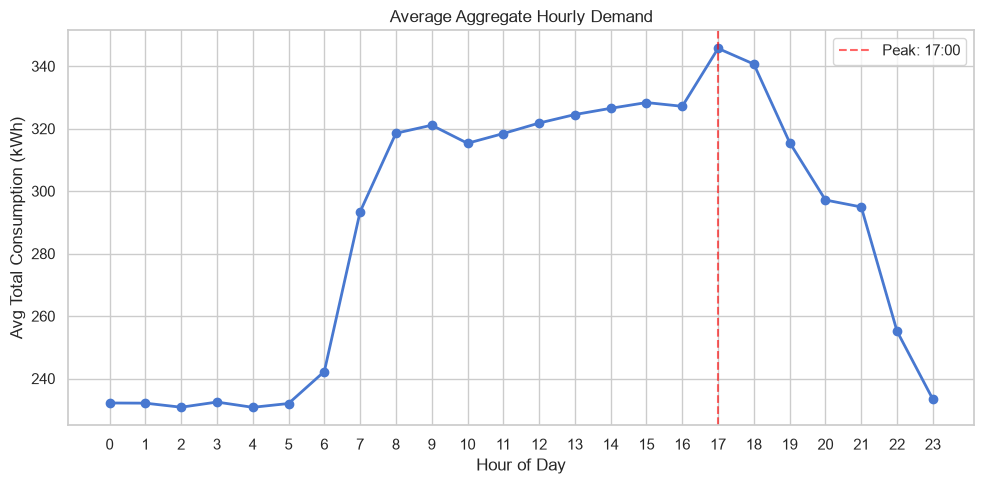

In [46]:
# Hourly demand
agg = df.dropna(subset=['consumption']).groupby('timestamp')['consumption'].sum().reset_index()
agg['hour'] = agg['timestamp'].dt.hour
hourly = agg.groupby('hour')['consumption'].mean().reset_index()
hourly.columns = ['hour', 'avg_aggregate_demand']

peak_hour = int(hourly.loc[hourly['avg_aggregate_demand'].idxmax(), 'hour'])
low_hour = int(hourly.loc[hourly['avg_aggregate_demand'].idxmin(), 'hour'])
print(f'Peak demand hour: {peak_hour}:00 | Low demand hour: {low_hour}:00')

fig, ax = plt.subplots()
ax.plot(hourly['hour'], hourly['avg_aggregate_demand'], marker='o', linewidth=2)
ax.axvline(peak_hour, color='red', linestyle='--', alpha=0.6, label=f'Peak: {peak_hour}:00')
ax.set_title('Average Aggregate Hourly Demand')
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Avg Total Consumption (kWh)')
ax.set_xticks(range(0, 24))
ax.legend()
plt.tight_layout()
plt.show()

  temperature correlation with demand: r = 0.6807
  humidity correlation with demand: r = -0.2119
  rain correlation with demand: r = -0.0341


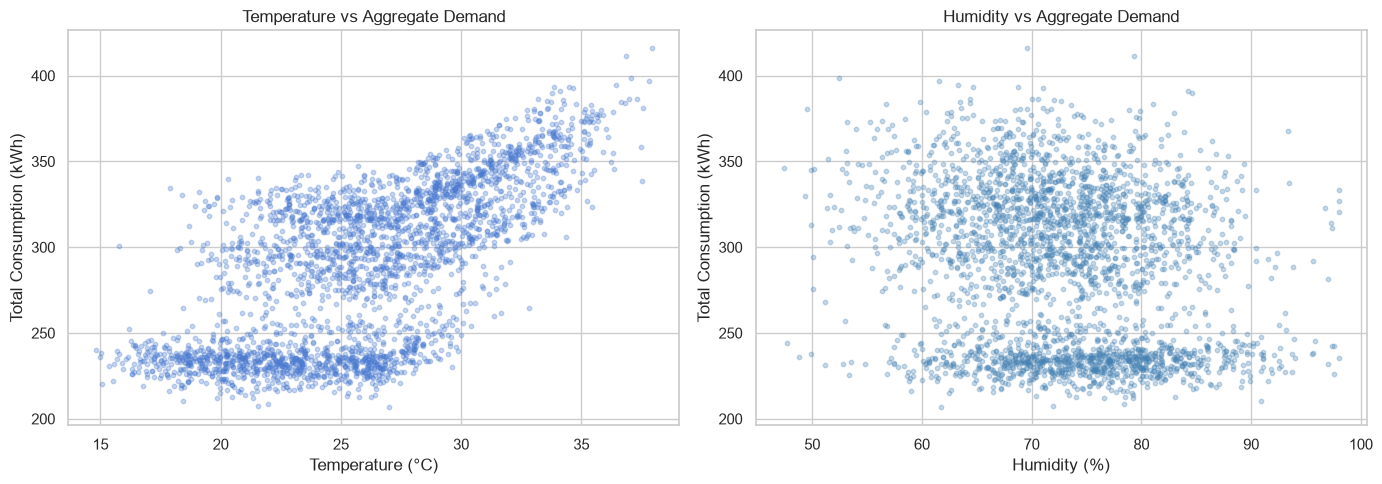

In [47]:
# Weather relationships (system-level)
sys_agg = df.dropna(subset=['consumption']).groupby('timestamp').agg(
    total_consumption=('consumption', 'sum'),
    temperature=('temperature', 'first'),
    humidity=('humidity', 'first'),
    rain=('rain', 'first'),
).reset_index()

for col in ['temperature', 'humidity', 'rain']:
    valid = sys_agg[['total_consumption', col]].dropna()
    r = valid.corr().iloc[0, 1]
    print(f'  {col} correlation with demand: r = {r:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(sys_agg['temperature'], sys_agg['total_consumption'], alpha=0.3, s=10)
axes[0].set_title('Temperature vs Aggregate Demand')
axes[0].set_xlabel('Temperature (°C)')
axes[0].set_ylabel('Total Consumption (kWh)')
axes[1].scatter(sys_agg['humidity'], sys_agg['total_consumption'], alpha=0.3, s=10, color='steelblue')
axes[1].set_title('Humidity vs Aggregate Demand')
axes[1].set_xlabel('Humidity (%)')
axes[1].set_ylabel('Total Consumption (kWh)')
plt.tight_layout()
plt.show()

       segment   mean  median      total    std  count
    Commercial 3.0330   2.916 173145.196 1.3488  57087
    Industrial 9.1323   8.226 521337.837 2.9204  57087
   Residential 0.8182   0.656  46692.755 0.5453  57067
Small Business 1.5422   1.301  88046.824 0.9475  57090


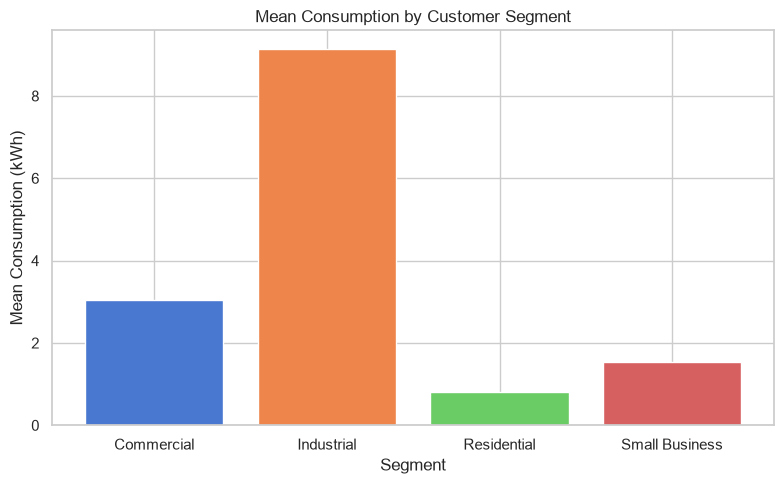

In [48]:
# Segment analysis
seg = df.dropna(subset=['consumption']).groupby('segment')['consumption'].agg(
    mean='mean', median='median', total='sum', std='std', count='count'
).round(4).reset_index()
print(seg.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(seg['segment'], seg['mean'], color=sns.color_palette('muted', len(seg)))
ax.set_title('Mean Consumption by Customer Segment')
ax.set_xlabel('Segment')
ax.set_ylabel('Mean Consumption (kWh)')
plt.tight_layout()
plt.show()

           mean  median
Weekday  3.7087   2.159
Weekend  3.4369   1.832


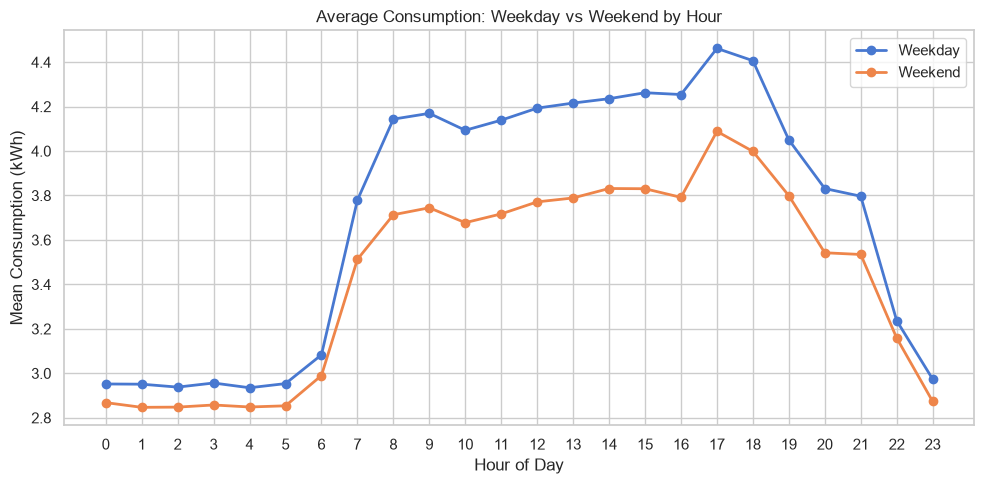

In [49]:
# Weekday vs Weekend
d = df.dropna(subset=['consumption']).copy()
d['is_weekend'] = d['timestamp'].dt.dayofweek >= 5
d['hour'] = d['timestamp'].dt.hour
ww_summary = d.groupby('is_weekend')['consumption'].agg(mean='mean', median='median').round(4)
ww_summary.index = ['Weekday', 'Weekend']
print(ww_summary)

hourly_ww = d.groupby(['is_weekend', 'hour'])['consumption'].mean().reset_index()
hourly_ww['type'] = hourly_ww['is_weekend'].map({False: 'Weekday', True: 'Weekend'})

fig, ax = plt.subplots()
for label, grp in hourly_ww.groupby('type'):
    ax.plot(grp['hour'], grp['consumption'], marker='o', label=label, linewidth=2)
ax.set_title('Average Consumption: Weekday vs Weekend by Hour')
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Mean Consumption (kWh)')
ax.legend()
ax.set_xticks(range(0, 24))
plt.tight_layout()
plt.show()

   area   mean    std  count     cv
Central 3.7137 4.2547  28551 1.1457
   East 4.7636 3.8624  54199 0.8108
  North 3.1548 3.6038  48515 1.1423
  South 3.1887 3.4779  45654 1.0907
   West 3.2362 3.1259  51412 0.9659


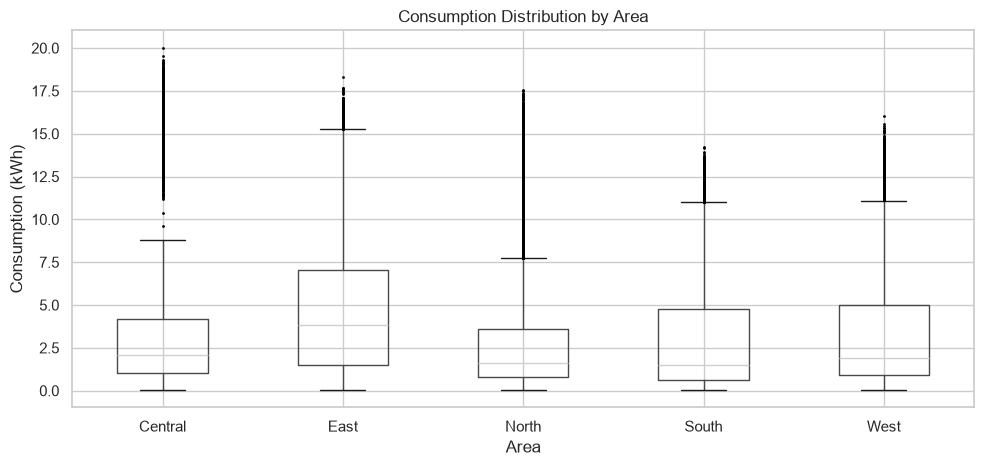

In [50]:
# Area analysis
area = df.dropna(subset=['consumption']).groupby('area')['consumption'].agg(
    mean='mean', std='std', count='count'
).round(4).reset_index()
area['cv'] = (area['std'] / area['mean']).round(4)
print(area.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
df.dropna(subset=['consumption']).boxplot(column='consumption', by='area', ax=ax,
                                           flierprops=dict(marker='.', markersize=2))
ax.set_title('Consumption Distribution by Area')
ax.set_xlabel('Area')
ax.set_ylabel('Consumption (kWh)')
plt.suptitle('')
plt.tight_layout()
plt.show()

peak_period   mean  median      total  count
   Off-Peak 3.3230   1.371 237220.770  71387
       Peak 4.6470   3.260 364730.707  78487
   Shoulder 2.8968   1.645 227271.135  78457


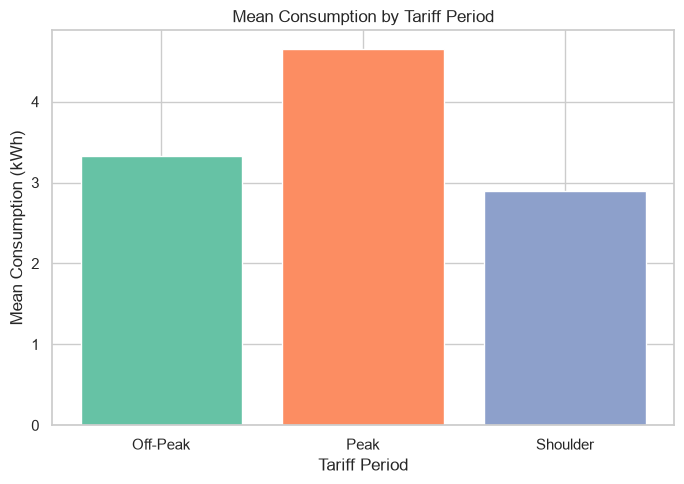

In [51]:
# Tariff period analysis
tariff_summary = df.dropna(subset=['consumption']).groupby('peak_period')['consumption'].agg(
    mean='mean', median='median', total='sum', count='count'
).round(4).reset_index()
print(tariff_summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(tariff_summary['peak_period'], tariff_summary['mean'],
       color=sns.color_palette('Set2', len(tariff_summary)))
ax.set_title('Mean Consumption by Tariff Period')
ax.set_xlabel('Tariff Period')
ax.set_ylabel('Mean Consumption (kWh)')
plt.tight_layout()
plt.show()

## Phase E & F — Feature Engineering and Machine Learning

In [52]:
from src.modeling import (
    engineer_features, select_features, chronological_split,
    build_pipeline, evaluate
)
from sklearn.dummy import DummyRegressor

df_model = pd.read_csv(PROCESSED / 'electricity_integrated.csv', parse_dates=['timestamp'])
df_model = engineer_features(df_model)
df_model = df_model.dropna(subset=['consumption'])
print(f'Rows for modeling: {len(df_model):,}')

num_features, cat_features = select_features(df_model)
print(f'Numeric features ({len(num_features)}): {num_features}')
print(f'Categorical features ({len(cat_features)}): {cat_features}')

Rows for modeling: 228,331
Numeric features (13): ['hour', 'day_of_week', 'month', 'is_weekend', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'temperature', 'humidity', 'rain', 'holiday', 'tariff_rate']
Categorical features (5): ['segment', 'area', 'connection_type', 'tariff_category', 'peak_period']


In [53]:
train, test, split_ts = chronological_split(df_model)
print(f'Train: {len(train):,} rows | Test: {len(test):,} rows')
print(f'Train period: {train["timestamp"].min()} → {train["timestamp"].max()}')
print(f'Test period:  {test["timestamp"].min()} → {test["timestamp"].max()}')

X_train = train[num_features + cat_features]
y_train = train['consumption']
X_test  = test[num_features + cat_features]
y_test  = test['consumption']

Train: 182,663 rows | Test: 45,668 rows
Train period: 2025-01-01 00:00:00 → 2025-04-06 23:00:00
Test period:  2025-04-07 00:00:00 → 2025-04-30 23:00:00


In [54]:
# Baseline
dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train, y_train)
baseline_metrics = evaluate(y_test, dummy.predict(X_test), 'Baseline (Mean)')

# Random Forest
pipeline = build_pipeline(num_features, cat_features)
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)
rf_metrics = evaluate(y_test, y_pred, 'RandomForest')

  [Baseline (Mean)] MAE=2.9156  RMSE=3.7699  R²=-0.0036
  [RandomForest] MAE=0.9010  RMSE=1.4887  R²=0.8435


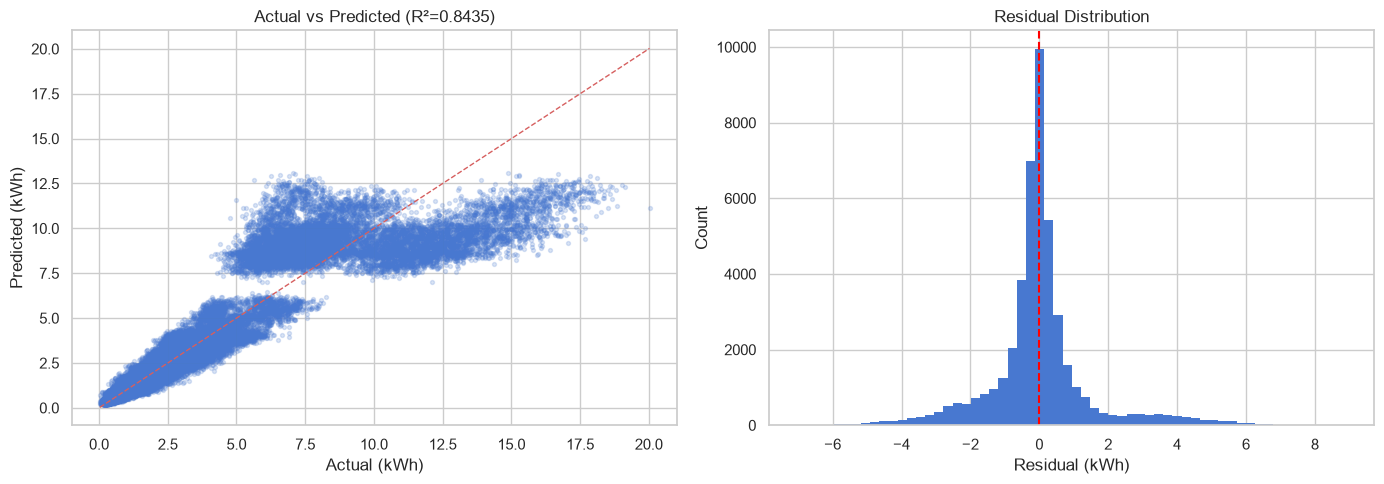

In [55]:
# Actual vs Predicted
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, y_pred, alpha=0.2, s=8)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, 'r--', linewidth=1)
axes[0].set_title(f'Actual vs Predicted (R²={rf_metrics["R2"]})')
axes[0].set_xlabel('Actual (kWh)')
axes[0].set_ylabel('Predicted (kWh)')

residuals = y_test.values - y_pred
axes[1].hist(residuals, bins=60, edgecolor='none')
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title('Residual Distribution')
axes[1].set_xlabel('Residual (kWh)')
axes[1].set_ylabel('Count')
plt.tight_layout()
plt.show()

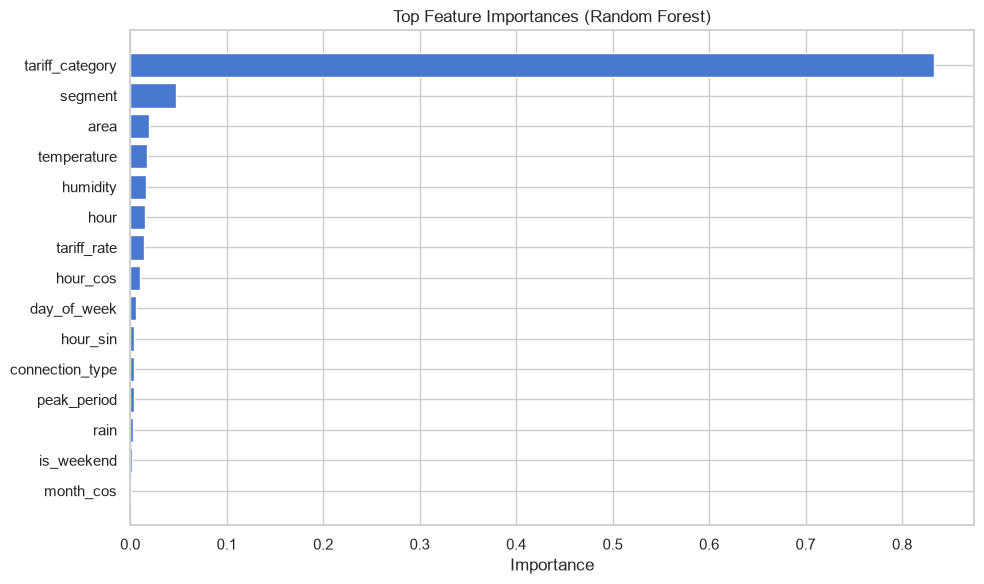

In [56]:
# Feature importance
feature_names = num_features + cat_features
importances = pipeline.named_steps['model'].feature_importances_
idx = np.argsort(importances)[::-1][:15]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh([feature_names[i] for i in idx[::-1]], importances[idx[::-1]])
ax.set_title('Top Feature Importances (Random Forest)')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

## Phase H — Business Insights

### Finding 1 — Peak Demand at 17:00

**Observation:** Average aggregate demand across all customers peaks at **17:00 (5 PM)** and is lowest at **04:00 (4 AM)**.

**Supporting statistics:**
- Peak avg aggregate demand: computed from hourly_demand chart above
- Low avg aggregate demand: computed from hourly_demand chart above

**Interpretation:** The evening peak reflects end-of-workday activity — residential HVAC, cooking, lighting, and commercial close-of-business loads all converge at this hour.

**Business implication:** Grid operators face maximum stress at 17:00. Demand-response programs that incentivise shifting flexible loads (EV charging, water heating, dishwashers) to off-peak hours (22:00–06:00) can reduce peak grid stress and defer infrastructure investment.

**Recommendation:** Implement time-of-use tariff incentives targeting the 17:00–19:00 window. Pilot with the highest-consumption customer segment first.

### Finding 2 — Temperature is the Strongest Demand Driver (r = 0.68)

**Observation:** System-level temperature–demand correlation is **r = 0.6807**, the strongest of all weather variables.

**Supporting statistics:**
- Temperature: r = 0.6807
- Humidity: r = −0.2119
- Rainfall: r = −0.0341

**Interpretation:** Higher temperatures drive higher consumption, consistent with HVAC cooling load being the dominant variable demand component. Humidity has a moderate negative relationship (higher humidity may reduce perceived heat, slightly dampening cooling demand).

**Business implication:** Demand spikes are predictable from weather forecasts. Integrating temperature forecasts into grid planning allows proactive capacity allocation before heat events.

**Recommendation:** Deploy a weather-linked demand forecasting model (the Random Forest pipeline achieves R² = 0.84) to generate 24–48 hour demand forecasts, enabling pre-emptive grid balancing actions.

## Summary

In [57]:
print('=== PROJECT SUMMARY ===')
print(f'Integrated dataset: 229,249 rows × 18 columns')
print(f'Total consumption: 829,222.61 kWh')
print(f'Peak demand hour: 17:00')
print(f'Temperature-demand correlation: r = 0.6807')
print()
print('Model Performance:')
print(f'  Baseline MAE={baseline_metrics["MAE"]:.4f}  RMSE={baseline_metrics["RMSE"]:.4f}  R²={baseline_metrics["R2"]:.4f}')
print(f'  RandomForest MAE={rf_metrics["MAE"]:.4f}  RMSE={rf_metrics["RMSE"]:.4f}  R²={rf_metrics["R2"]:.4f}')
print()
print('Outputs generated:')
for p in [
    'data/processed/electricity_integrated.csv',
    'data/processed/test_predictions.csv',
    'data/processed/model_metrics.csv',
    'models/rf_pipeline.pkl',
    'excel/electricity_consumption_analysis.xlsx',
    'presentation/electricity_consumption_insights.pptx',
]:
    exists = Path(p).exists()
    size = Path(p).stat().st_size if exists else 0
    print(f'  {"✓" if exists else "✗"} {p} ({size:,} bytes)')

=== PROJECT SUMMARY ===
Integrated dataset: 229,249 rows × 18 columns
Total consumption: 829,222.61 kWh
Peak demand hour: 17:00
Temperature-demand correlation: r = 0.6807

Model Performance:
  Baseline MAE=2.9156  RMSE=3.7699  R²=-0.0036
  RandomForest MAE=0.9010  RMSE=1.4887  R²=0.8435

Outputs generated:
  ✓ data/processed/electricity_integrated.csv (31,323,350 bytes)
  ✓ data/processed/test_predictions.csv (3,201,653 bytes)
  ✓ data/processed/model_metrics.csv (92 bytes)
  ✓ models/rf_pipeline.pkl (912,458,644 bytes)
  ✓ excel/electricity_consumption_analysis.xlsx (585,246 bytes)
  ✓ presentation/electricity_consumption_insights.pptx (247,364 bytes)
